# Explorador

Selecciona Ishii o MMC2 en la primera celda y ejecuta **Ejecutar todo**.
El notebook presenta dos partes: evaluación de mediciones ocultadas y candidatos reales.
Lee resultados existentes y muestra gráficos.


In [ ]:
# 1. CONFIGURACIÓN
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

DATASET = "ishii"  # "ishii" o "mmc2"
METABOLITO = "fum[c]"  # fum[c], pep[c], s7p[c], succ[c]
EXPERIMENTO = "perturbation"  # Opción de visualización.
POLITICA = "available"  # available o supported_plus_baseline
SOLO_CASOS_COMUNES = (True) # comparar sobre los mismos casos aceptados por los tres
PATRON = None  # para real_patterns: None = todos; o "P01", "P02", etc.
UTA_PROYECTO= None
METHODS = ["SimpleImputer", "KNNImputer", "IterativeImputer"]
NAMES = {
    "SimpleImputer": "Mediana",
    "KNNImputer": "KNN",
    "IterativeImputer": "Iterative",
}
COLORS = {
    "SimpleImputer": "#777777",
    "KNNImputer": "#16869b",
    "IterativeImputer": "#b5548c",
}
LABELS = {
    "fum[c]": "Fumarato",
    "pep[c]": "PEP",
    "s7p[c]": "s7p",
    "succ[c]": "Succinato",
}
assert DATASET in ("ishii", "mmc2")
assert METABOLITO in LABELS
assert POLITICA in ("available", "supported_plus_baseline")


candidates = [Path.cwd(), Path.cwd() / "IPre_Normalizacion_Imputacion",
    Path.cwd().parent,]
ROOT = next(
    (p for p in candidates
    if (p / "normalizacion").is_dir()
    and (p / "ejecutar_imputacion.py").is_file()), None,)

if ROOT is None:
    raise FileNotFoundError("No encuentro el proyecto. Define la ruta del proyecto en candidates.")

sys.path.insert(0, str(ROOT))
RES = ROOT / "resultados" / DATASET
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
print(f"Proyecto: {ROOT}\nBase seleccionada: {DATASET}\nResultados: {RES}")


Proyecto: c:\Users\HP 440 G10\OneDrive\Escritorio\IPre_PedroSaa
Base seleccionada: ishii
Resultados: c:\Users\HP 440 G10\OneDrive\Escritorio\IPre_PedroSaa\resultados\ishii


In [2]:
# Leer una única base y sus resultados ya calculados.
def leer_csv(archivo, index_col=None):
    if not archivo.is_file():
        raise FileNotFoundError(
            f"Falta {archivo}. Ejecuta primero el análisis de {DATASET}."
        )
    return pd.read_csv(archivo, index_col=index_col)


from apoyo import describir  # noqa: E402

original = leer_csv(
    ROOT / "normalizacion" / f"matriz_{DATASET}_mM.csv", index_col=0
)
pred = leer_csv(RES / "validacion/predicciones.csv")
casos = leer_csv(RES / "validacion/casos_comunes.csv")
reales = leer_csv(RES / "imputacion/candidatos_y_soporte.csv")
casillas = leer_csv(RES / "imputacion/casillas_comunes.csv")
estadisticas = leer_csv(RES / "imputacion/estadisticas_antes_despues.csv")
mascaras = json.loads(
    (RES / "validacion/mascaras.json").read_text(encoding="utf-8")
)
manifest = json.loads((RES / "manifest.json").read_text(encoding="utf-8"))
assert manifest["dataset"] == DATASET
print(f"{len(original)} muestras y {len(original.columns)} metabolitos.")
print("Pruebas disponibles:", ", ".join(pred.experiment.unique()))
if DATASET == "mmc2":
    display(
        Markdown(
            (
                "**MMC2:** no hay prueba por serie equivalente a "
                "Ishii. Glucosa se excluye como consulta "
                "evaluada porque su concentración está revelada "
                "en la referencia de normalización."
            )
        )
    )


30 muestras y 7 metabolitos.
Pruebas disponibles: analytical_series, perturbation, real_patterns


## Datos originales

Cada fila representa una muestra o condición; cada columna, un metabolito. `NaN` significa ausencia. Las posiciones del gráfico identifican muestras. Todas las concentraciones mostradas están en mM.


,fum[c],pep[c],s7p[c],succ[c],pyr[c],akg[c],cit[c]
sample_id,,,,,,,
KO01,0.0563,0.0786,0.1360,0.1120,NaN,0.0372,NaN
KO02,0.0521,0.0275,0.0885,0.0589,0.135,0.0462,0.02480
KO03,0.0372,0.0188,0.0678,0.0549,0.258,NaN,0.03920
KO04,NaN,NaN,0.2100,0.1270,NaN,NaN,0.00162
KO05,0.0710,0.0130,0.8690,0.1080,NaN,NaN,0.02310
KO05x,NaN,NaN,2.6900,0.1790,NaN,NaN,0.00593
KO06,0.0869,0.0616,0.1800,0.0686,0.254,0.0469,0.04660
KO07,0.0648,0.0664,0.1460,0.0552,0.153,0.0366,0.03180
KO08,0.0862,0.0395,0.2720,0.0539,0.113,0.0520,0.05180


,observados,faltantes,media_mM,mediana_mM,SD_mM
fum[c],23,7,0.05927,0.05630,0.02175
pep[c],22,8,0.08240,0.07370,0.06176
s7p[c],29,1,0.34743,0.18000,0.54637
succ[c],27,3,0.07867,0.06860,0.03053
pyr[c],14,16,0.22229,0.23850,0.09485
akg[c],11,19,0.05248,0.04810,0.02177
cit[c],12,18,0.03516,0.03305,0.02334


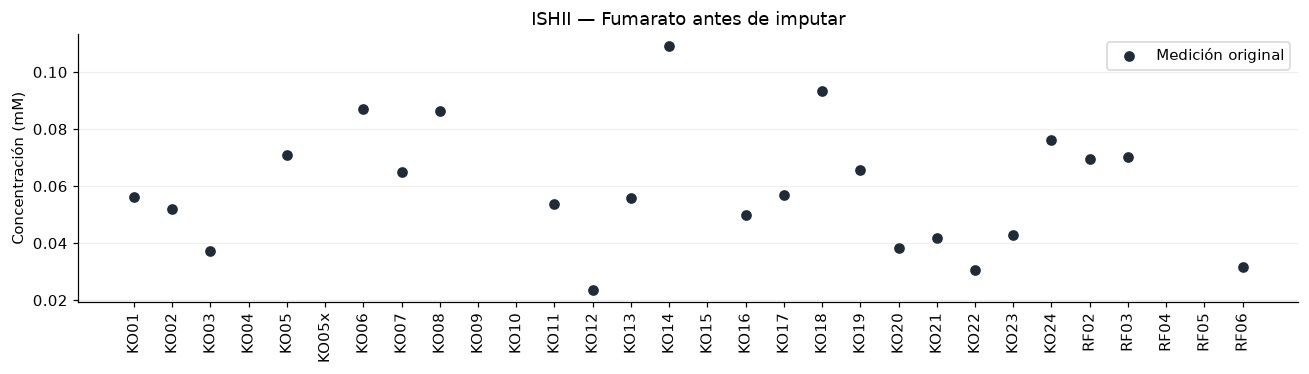

In [3]:
display(original.round(5))
resumen_original = pd.DataFrame(
    {
        "observados": original.count(),
        "faltantes": original.isna().sum(),
        "media_mM": original.mean(),
        "mediana_mM": original.median(),
        "SD_mM": original.std(ddof=1),
    }
)
display(resumen_original.round(5))
fig, ax = plt.subplots(figsize=(12, 3.5))
x = np.arange(len(original))
ax.scatter(x, original[METABOLITO], color="#202b38", label="Medición original")
ax.set_xticks(x, original.index, rotation=90)
ax.set_ylabel("Concentración (mM)")
ax.set_title(f"{DATASET.upper()} — {LABELS[METABOLITO]} antes de imputar")
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


## Sección 1 — Evaluación: valor conocido ocultado frente a valor imputado

Aquí la medición original que se ocultó al modelo. El error compara esa medición con su estimación. Los métodos reciben las mismas máscaras.

- `available`: incluye todos los candidatos finitos, incluso sustituciones generales o ajustes no convergentes.
- `supported_plus_baseline`: acepta solo predicciones con soporte de KNN e Iterative y conserva la mediana como referencia general. Esa excepción no convierte la mediana en una predicción individual con soporte.
- `SOLO_CASOS_COMUNES=True`: compara únicamente los casos aceptados por los tres métodos.




In [4]:
# Mostrar qué oculta cada patrón real.
display(
    pd.DataFrame(
        [
            {
                "patron": p["pattern_id"],
                "variables_ocultas": ", ".join(p["hidden"]),
                "objetivos_evaluados": ", ".join(p["score"]),
                "muestras_origen": ", ".join(p["source_samples"]),
            }
            for p in mascaras["patterns"]
        ]
    )
)

if EXPERIMENTO not in set(pred.experiment):
    raise ValueError(
        f"Prueba no disponible: {EXPERIMENTO}. "
        f"Opciones: {list(pred.experiment.unique())}"
    )
base = pred[
    (pred.experiment == EXPERIMENTO) & (pred.metabolite_id == METABOLITO)
].copy()
if EXPERIMENTO == "real_patterns" and PATRON is not None:
    trials = {
        t["trial_id"] for t in mascaras["trials"] if t["pattern_id"] == PATRON
    }
    if not trials:
        raise ValueError(f"Patrón sin ensayos elegibles: {PATRON}.")
    base = base[base.trial_id.isin(trials)].copy()
criterios = casos[casos.policy == POLITICA]
base = base.merge(
    criterios[["method", "case_id", "responded", "common_methods"]],
    on=["method", "case_id"],
    validate="one_to_one",
)
base["aceptado"] = base.responded
comunes = set(base.loc[base.common_methods, "case_id"])
comparacion = base[base.aceptado].copy()
if SOLO_CASOS_COMUNES:
    comparacion = comparacion[comparacion.common_methods].copy()
rows = []
for method in METHODS:
    propios = base[(base.method == method) & base.aceptado]
    seleccion = comparacion[comparacion.method == method]
    attempts = int((base.method == method).sum())
    rows.append(
        {
            "metodo": NAMES[method],
            "intentos": attempts,
            "respuestas_propias": len(propios),
            "cobertura_propia_%": (
                100 * len(propios) / attempts if attempts else np.nan
            ),
            "casos_comunes": len(comunes),
            "casos_graficados": len(seleccion),
            "MAE_mM_seleccion": seleccion.absolute_error_mM.mean(),
            "MAE_R_seleccion": seleccion.absolute_error_R.mean(),
        }
    )
display(pd.DataFrame(rows).round(6))
if comparacion.empty:
    display(
        Markdown(
            (
                "**No hay casos aceptados para esta selección.** "
                "Puedes explorar `available` o desactivar casos "
                "comunes, indicando que las comparaciones "
                "podrían usar distintas celdas."
            )
        )
    )
else:
    display(
        comparacion[
            [
                "sample_id",
                "trial_id",
                "method",
                "truth_mM",
                "estimate_mM",
                "absolute_error_mM",
                "support",
                "mechanism",
            ]
        ].round(6)
    )


,patron,variables_ocultas,objetivos_evaluados,muestras_origen
0,P01,"fum[c], pep[c], pyr[c], akg[c]","fum[c], pep[c]","KO04, KO05x"
1,P02,"fum[c], pep[c], pyr[c], akg[c], cit[c]","fum[c], pep[c]","KO09, KO15, RF05"
2,P03,"fum[c], pep[c], s7p[c], succ[c], pyr[c], akg[c...","fum[c], pep[c], s7p[c], succ[c]",KO10
3,P04,"fum[c], pep[c], succ[c], pyr[c], akg[c], cit[c]","fum[c], pep[c], succ[c]",RF04
4,P05,"pep[c], akg[c], cit[c]",pep[c],KO21
5,P06,"succ[c], akg[c], cit[c]",succ[c],RF02


,metodo,intentos,respuestas_propias,cobertura_propia_%,casos_comunes,casos_graficados,MAE_mM_seleccion,MAE_R_seleccion
0,Mediana,23,23,100.0,23,23,0.017250,0.031464
1,KNN,23,23,100.0,23,23,0.022097,0.040305
2,Iterative,23,23,100.0,23,23,0.022466,0.040978


,sample_id,trial_id,method,truth_mM,estimate_mM,absolute_error_mM,support,mechanism
0,KO01,perturbation:KO01:fum[c],SimpleImputer,0.0563,0.056350,0.000050,training_only,training_median
1,KO01,perturbation:KO01:fum[c],KNNImputer,0.0563,0.076133,0.019833,supported,neighbor_mean
2,KO01,perturbation:KO01:fum[c],IterativeImputer,0.0563,0.085303,0.029003,supported,conditional_iterative_model_with_internal_fills
3,KO02,perturbation:KO02:fum[c],SimpleImputer,0.0521,0.056550,0.004450,training_only,training_median
4,KO02,perturbation:KO02:fum[c],KNNImputer,0.0521,0.060533,0.008433,supported,neighbor_mean
...,...,...,...,...,...,...,...,...
64,RF03,perturbation:RF03:fum[c],KNNImputer,0.0702,0.040433,0.029767,supported,neighbor_mean
65,RF03,perturbation:RF03:fum[c],IterativeImputer,0.0702,0.035433,0.034767,supported,conditional_iterative_model_with_internal_fills
66,RF06,perturbation:RF06:fum[c],SimpleImputer,0.0315,0.056100,0.024600,training_only,training_median
67,RF06,perturbation:RF06:fum[c],KNNImputer,0.0315,0.062200,0.030700,supported,neighbor_mean


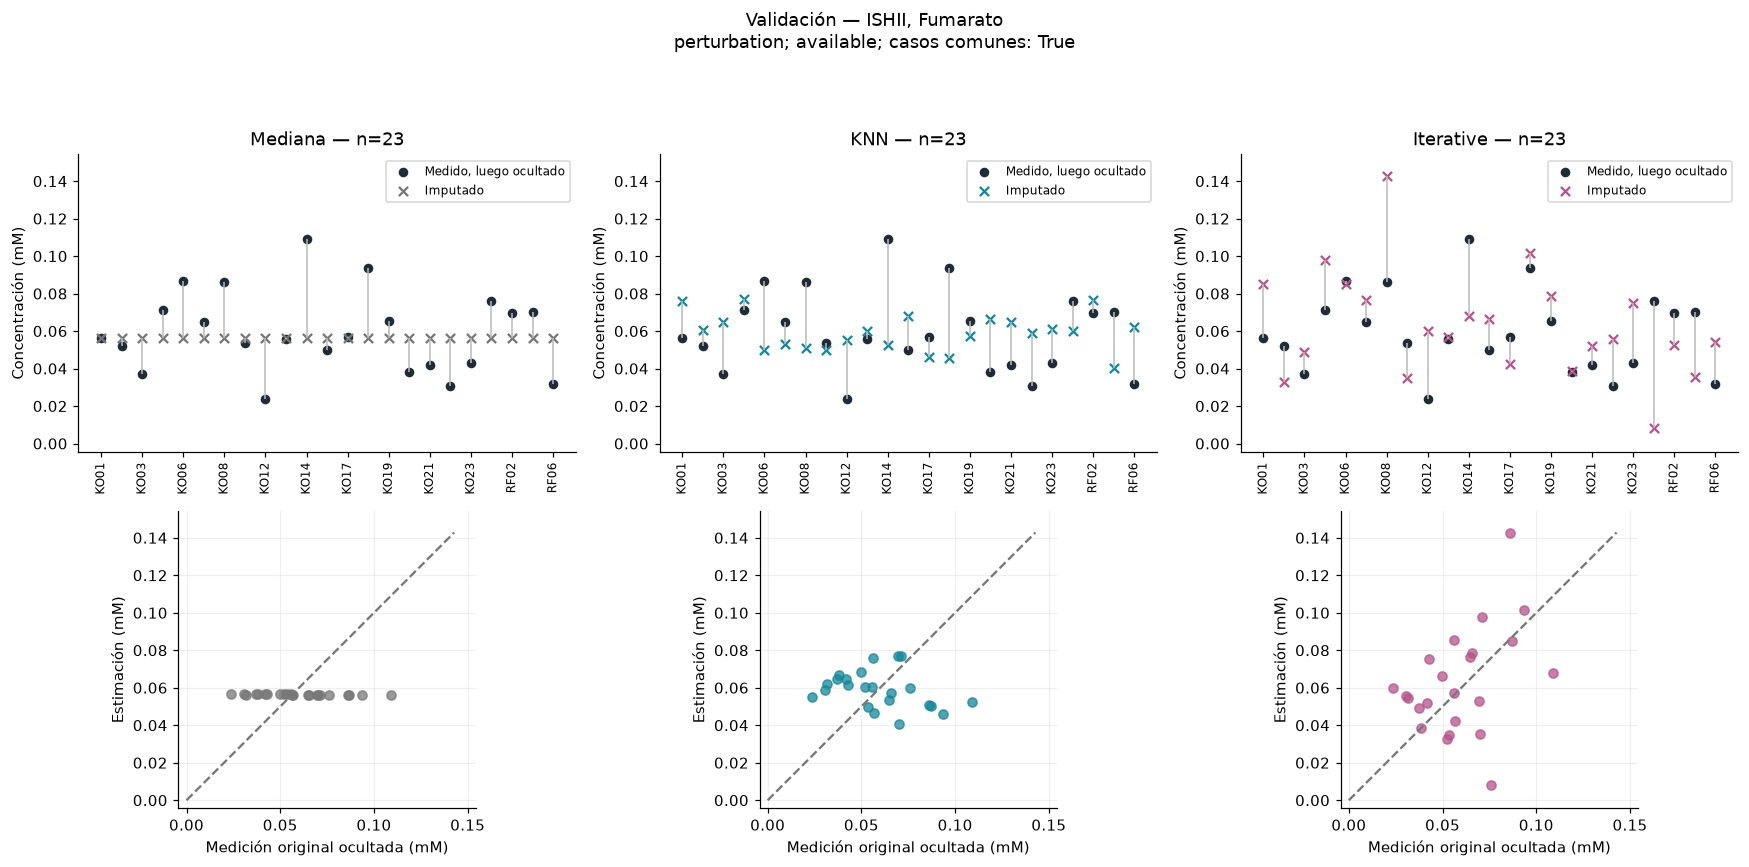

In [5]:
# Dos perspectivas de los mismos casos: comparación pareada y dispersión
# real vs estimado.
if not comparacion.empty:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    maximo = max(
        comparacion.truth_mM.max(), comparacion.estimate_mM.max(), 0.001
    )
    for j, method in enumerate(METHODS):
        d = comparacion[comparacion.method == method].sort_values("case_id")
        ax = axes[0, j]
        xx = np.arange(len(d))
        ax.vlines(xx, d.truth_mM, d.estimate_mM, color="#bbbbbb", lw=1)
        ax.scatter(
            xx,
            d.truth_mM,
            color="#202b38",
            s=28,
            label="Medido, luego ocultado",
        )
        ax.scatter(
            xx,
            d.estimate_mM,
            color=COLORS[method],
            marker="x",
            s=36,
            label="Imputado",
        )
        labels = [
            (
                f"{r.sample_id}/{r.trial_id.split(':')[-1]}"
                if EXPERIMENTO == "real_patterns"
                else r.sample_id
            )
            for r in d.itertuples()
        ]
        step = max(1, int(np.ceil(len(d) / 18)))
        ax.set_xticks(xx[::step], labels[::step], rotation=90, fontsize=8)
        ax.set_title(f"{NAMES[method]} — n={len(d)}")
        ax.set_ylabel("Concentración (mM)")
        ax.set_ylim(-0.03 * maximo, 1.08 * maximo)
        ax.legend(fontsize=8)
        ax = axes[1, j]
        ax.scatter(d.truth_mM, d.estimate_mM, color=COLORS[method], alpha=0.75)
        ax.plot([0, maximo], [0, maximo], "--", color="#777777")
        ax.set(
            xlabel="Medición original ocultada (mM)",
            ylabel="Estimación (mM)",
            xlim=(-0.03 * maximo, 1.08 * maximo),
            ylim=(-0.03 * maximo, 1.08 * maximo),
        )
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.2)
    fig.suptitle(
        f"Validación — {DATASET.upper()}, {LABELS[METABOLITO]}\n"
        f"{EXPERIMENTO}; {POLITICA}; casos comunes: {SOLO_CASOS_COMUNES}"
    )
    plt.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()


In [6]:
# Estadísticas de las verdades ocultadas y sus estimaciones SOBRE LOS
# CASOS EVALUADOS.
# No se confunden con estadísticas de toda la cohorte ni de los huecos reales.
resumen_validacion = []
for method in METHODS:
    d = comparacion[comparacion.method == method]
    for tipo, columna in [
        ("Mediciones ocultadas", "truth_mM"),
        ("Estimaciones", "estimate_mM"),
    ]:
        resumen_validacion.append(
            {
                "metodo": NAMES[method],
                "datos": tipo,
                "n": d[columna].count(),
                **describir(d[columna]),
            }
        )
display(pd.DataFrame(resumen_validacion).round(6))


,metodo,datos,n,mean_mM,median_mM,SD_mM,IQR_mM,CV_pct,CV_status
0,Mediana,Mediciones ocultadas,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
1,Mediana,Estimaciones,23,0.056307,0.056100,0.000224,0.000450,0.398300,interpretable
2,KNN,Mediciones ocultadas,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
3,KNN,Estimaciones,23,0.059075,0.059833,0.009910,0.013150,16.774510,interpretable
4,Iterative,Mediciones ocultadas,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
5,Iterative,Estimaciones,23,0.063048,0.056995,0.028423,0.031967,45.081743,interpretable


## Sección 2 — Completar huecos que no tenían medición

El gráfico distingue valores medidos de imputados. Las estadísticas se calculan sobre todas las muestras de la base seleccionada, omitiendo los valores pendientes. Con `SOLO_CASOS_COMUNES=True`, cada método completa exactamente las mismas celdas aceptadas por los tres. Una intersección vacía deja las estadísticas originales sin cambios.


In [7]:
# Las decisiones de aceptación ya están registradas por el ejecutor.
criterios = casillas[casillas.policy == POLITICA]
r = reales.merge(
    criterios[
        ["method", "sample_id", "metabolite_id", "selected", "common_methods"]
    ],
    on=["method", "sample_id", "metabolite_id"],
    validate="one_to_one",
)
r["aceptado"] = r.selected
if SOLO_CASOS_COMUNES:
    r["aceptado"] = r.common_methods

matrices = {}
for method in METHODS:
    matriz = original.copy()
    for registro in r[(r.method == method) & r.aceptado].itertuples():
        assert pd.isna(
            original.loc[registro.sample_id, registro.metabolite_id]
        )
        matriz.loc[registro.sample_id, registro.metabolite_id] = (
            registro.estimate_mM
        )
    matrices[method] = matriz

print(f"Candidatos en los cuatro objetivos: {len(reales) // len(METHODS)}")
display(
    r[r.metabolite_id == METABOLITO][
        [
            "sample_id",
            "method",
            "estimate_mM",
            "aceptado",
            "support",
            "mechanism",
        ]
    ].round(6)
)
if not original[METABOLITO].isna().any():
    display(
        Markdown(
            (
                "**Este metabolito no tiene huecos reales en la "
                "base seleccionada.**"
            )
        )
    )


Candidatos en los cuatro objetivos: 19


,sample_id,method,estimate_mM,aceptado,support,mechanism
0,KO04,SimpleImputer,0.056300,True,training_only,training_median
2,KO04,KNNImputer,0.078300,True,limited_support,neighbor_mean
4,KO04,IterativeImputer,0.044900,True,supported,conditional_iterative_model_with_internal_fills
6,KO05x,SimpleImputer,0.056100,True,training_only,training_median
8,KO05x,KNNImputer,0.076167,True,supported,neighbor_mean
10,KO05x,IterativeImputer,0.145357,True,supported,conditional_iterative_model_with_internal_fills
12,KO09,SimpleImputer,0.056300,True,training_only,training_median
14,KO09,KNNImputer,0.052633,True,limited_support,neighbor_mean
16,KO09,IterativeImputer,0.058676,True,supported,conditional_iterative_model_with_internal_fills
18,KO10,SimpleImputer,0.056300,True,training_only,training_median


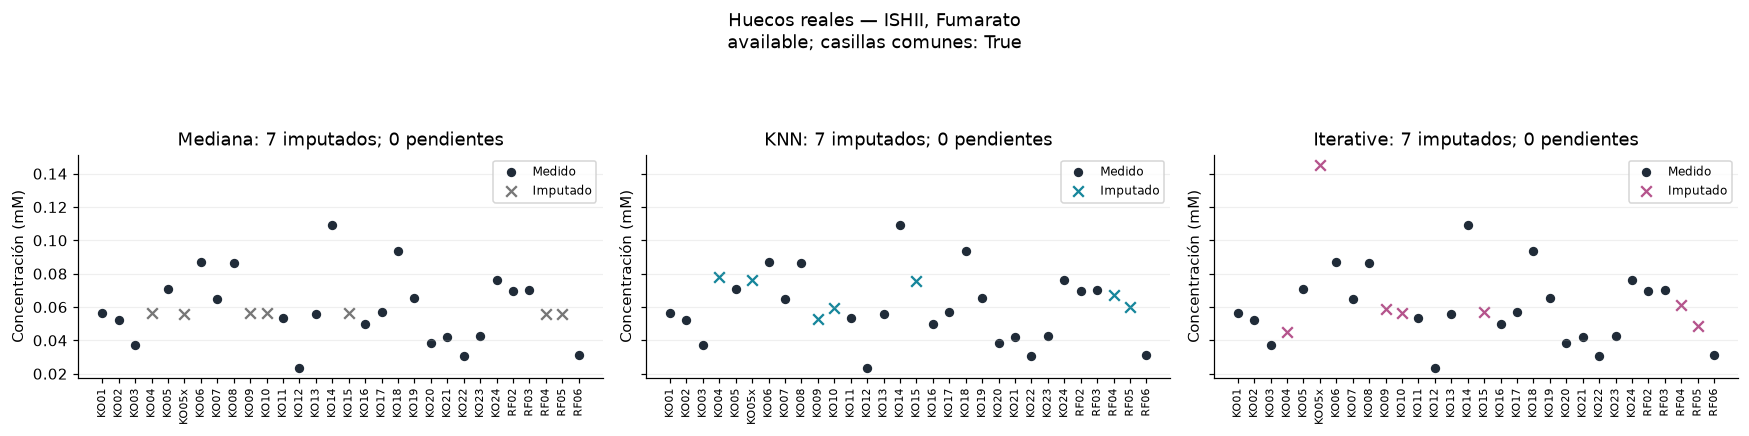

,method,stage,total_samples,observed,imputed,pending,mean_mM,median_mM,SD_mM,IQR_mM,CV_pct,CV_status
14,SimpleImputer,before,30,23,0,7,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
21,SimpleImputer,after,30,23,7,0,0.058553,0.056300,0.018988,0.018225,32.428764,interpretable
42,KNNImputer,before,30,23,0,7,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
49,KNNImputer,after,30,23,7,0,0.061087,0.059766,0.019766,0.024050,32.356591,interpretable
70,IterativeImputer,before,30,23,0,7,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
77,IterativeImputer,after,30,23,7,0,0.061173,0.056538,0.024948,0.024226,40.781683,interpretable


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
x = np.arange(len(original))
observed = original[METABOLITO].notna()
for ax, method in zip(axes, METHODS):
    column = matrices[method][METABOLITO]
    imputed = ~observed & column.notna()
    pending = ~observed & column.isna()
    ax.scatter(
        x[observed],
        original.loc[observed, METABOLITO],
        color="#202b38",
        s=26,
        label="Medido",
    )
    ax.scatter(
        x[imputed],
        column[imputed],
        color=COLORS[method],
        marker="x",
        s=48,
        label="Imputado",
    )
    ax.set_xticks(x, original.index, rotation=90, fontsize=7)
    ax.set_title(
        f"{NAMES[method]}: {int(imputed.sum())} imputados; "
        f"{int(pending.sum())} pendientes"
    )
    ax.set_ylabel("Concentración (mM)")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle(
    f"Huecos reales — {DATASET.upper()}, {LABELS[METABOLITO]}\n"
    f"{POLITICA}; casillas comunes: {SOLO_CASOS_COMUNES}"
)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

# Leer las estadísticas que corresponden a las casillas mostradas.
alcance = "common_methods" if SOLO_CASOS_COMUNES else "own"
resumen = estadisticas[
    (estadisticas.policy == POLITICA)
    & (estadisticas.scope == alcance)
    & (estadisticas.metabolite_id == METABOLITO)
]
display(
    resumen[
        [
            "method",
            "stage",
            "total_samples",
            "observed",
            "imputed",
            "pending",
            "mean_mM",
            "median_mM",
            "SD_mM",
            "IQR_mM",
            "CV_pct",
            "CV_status",
        ]
    ].round(6)
)
